# Analysis of geneological structure  

In [2]:
import json
from vocabulary_functions import get_parents, get_family_dictionary
import matplotlib.pyplot as plt
import numpy as np 


In [3]:
def extract_data(pth):
    with open(pth) as f:
        vocab = json.load(f)
    families = get_family_dictionary(vocab)
    parents = get_parents(vocab)
    return vocab, families, parents

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


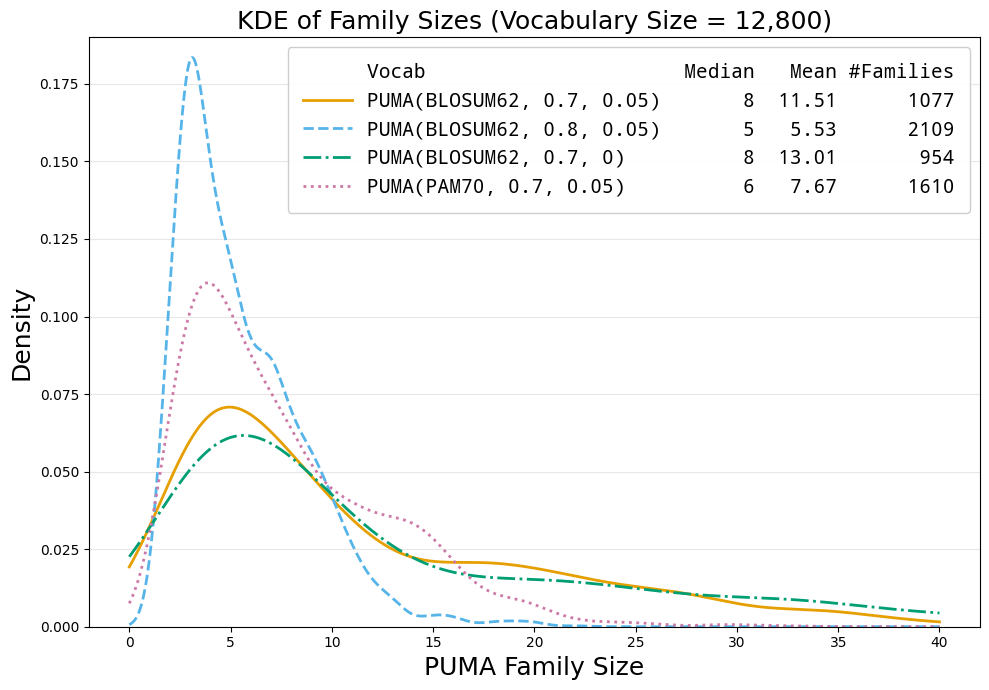

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


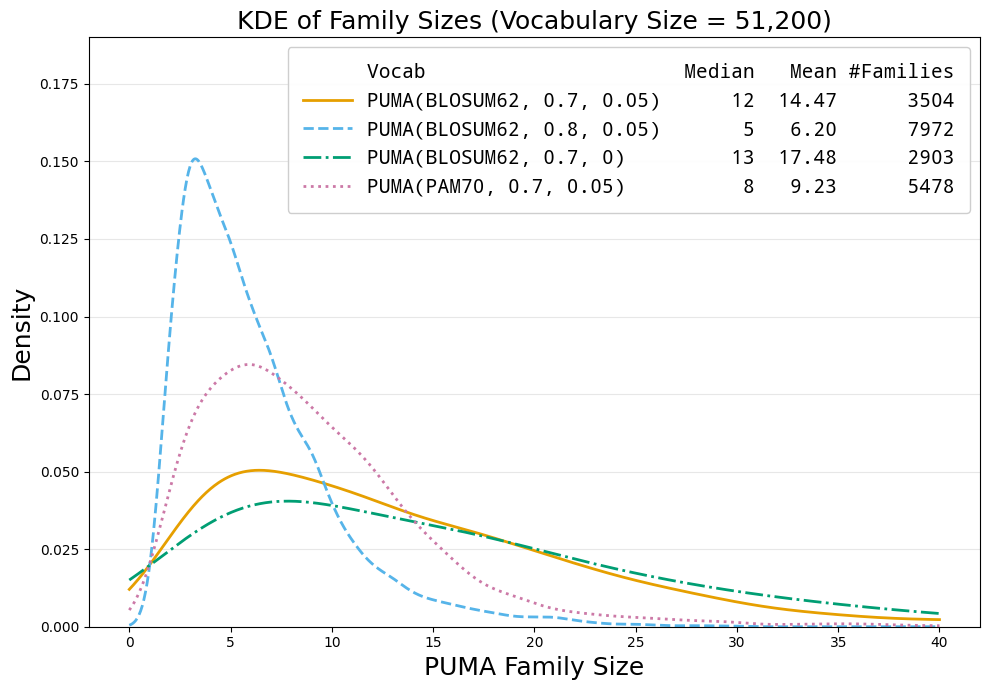

In [ ]:
# Same KDE plots, but with the legend rendered as a table
# (columns: Vocab | Median | Mean | #Families)
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
# Requires models trained with multiprocess_train.py
file_paths = [
    "/cta/share/users/mutbpe/tokenizers/blosum62/uniref50_mutbpe_0.7_3_12_0.05_12800.json",
    "/cta/share/users/mutbpe/tokenizers/blosum62/uniref50_mutbpe_0.8_3_12_0.05_12800.json",
    "/cta/share/users/mutbpe/tokenizers/blosum62/uniref50_mutbpe_0.7_3_12_0_12800.json",
    "/cta/share/users/mutbpe/tokenizers/pam70/uniref50_mutbpe_0.7_3_12_0.05_12800.json",
    "/cta/share/users/mutbpe/tokenizers/blosum62/uniref50_mutbpe_0.7_3_12_0.05_51200.json",
    "/cta/share/users/mutbpe/tokenizers/blosum62/uniref50_mutbpe_0.8_3_12_0.05_51200.json",
    "/cta/share/users/mutbpe/tokenizers/blosum62/uniref50_mutbpe_0.7_3_12_0_51200.json",
    "/cta/share/users/mutbpe/tokenizers/pam70/uniref50_mutbpe_0.7_3_12_0.05_51200.json",
]

file_labels = [
    "PUMA(BLOSUM62, 0.7, 0.05)", "PUMA(BLOSUM62, 0.8, 0.05)", "PUMA(BLOSUM62, 0.7, 0)", "PUMA(PAM70, 0.7, 0.05)",  
    "PUMA(BLOSUM62, 0.7, 0.05)", "PUMA(BLOSUM62, 0.8, 0.05)", "PUMA(BLOSUM62, 0.7, 0)", "PUMA(PAM70, 0.7, 0.05)",  
]

# Colorblind-friendly colors (Okabe-Ito palette)
CB_COLORS = ['#E69F00', '#56B4E9', '#009E73','#CC79A7', '#D55E00', '#0072B2',  '#F0E442']


# Column widths (in monospace characters)
W_VOCAB, W_MED, W_MEAN, W_FAM = 26, 7, 7, 10

def _row(vocab, med, mean, fam):
    return (f"{vocab:<{W_VOCAB}}{med:>{W_MED}}{mean:>{W_MEAN}}{fam:>{W_FAM}}")

HEADER = _row("Vocab", "Median", "Mean", "#Families")


def plot_kde_group_table(ax, files_to_plot, labels_to_plot, sub_title,
                         color_offset=0, log_correct=False):
    linestyles = ['-', '--', '-.', ':']

    collected_data = []
    for f_path in files_to_plot:
        _, families, parents = extract_data(f_path)
        collected_data.append([len(families[p]) for p in parents])

    x_grid = np.linspace(0.0001, 40, 1000)

    handles, labels = [], []
    for i, data in enumerate(collected_data):
        if not data:
            continue

        mean_val = np.mean(data)
        median_val = np.median(data)
        density = gaussian_kde(data)
        y_vals = density(x_grid)

        if log_correct:
            kde_log = gaussian_kde(np.log(data))
            y_vals = kde_log(np.log(x_grid)) * (1 / x_grid)

        c = CB_COLORS[(i + color_offset) % len(CB_COLORS)]
        ls = linestyles[i % len(linestyles)]

        line, = ax.plot(x_grid, y_vals, color=c, linestyle=ls, linewidth=2)
        handles.append(line)
        labels.append(_row(labels_to_plot[i], f"{int(median_val):d}",
                           f"{mean_val:.2f}", f"{len(data)}"))

    # Header row: invisible handle so the text lines up with the entries below
    header_handle = Line2D([], [], linestyle='none', marker='none', color='none')
    handles.insert(0, header_handle)
    labels.insert(0, HEADER)

    ax.set_title(sub_title, fontsize=18)
    ax.set_xlabel('PUMA Family Size', fontsize=18)
    ax.set_ylabel('Density', fontsize=18)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim([0, 0.19])

    leg = ax.legend(handles, labels, loc='upper right',
                    prop={"family": 'Noto Mono', "size": 14},
                    handlelength=2.5, handletextpad=0.8,
                    labelspacing=0.45, borderpad=0.8, framealpha=0.95)
    # Header kept in regular weight so its columns stay aligned with the rows
    # (bold monospace is slightly wider). Uncomment to bold it:
    # leg.get_texts()[0].set_fontweight('bold')
    return leg


# Plot 1
fig1, ax1 = plt.subplots(figsize=(10, 7))
plot_kde_group_table(
    ax=ax1,
    files_to_plot=file_paths[0:4],
    labels_to_plot=file_labels[0:4],
    sub_title='KDE of Family Sizes (Vocabulary Size = 12,800)',
    color_offset=0
)
plt.tight_layout()
# plt.savefig("prelim_kde_a.eps")
plt.show()

# Plot 2
fig2, ax2 = plt.subplots(figsize=(10, 7))
plot_kde_group_table(
    ax=ax2,
    files_to_plot=file_paths[4:],
    labels_to_plot=file_labels[4:],
    sub_title='KDE of Family Sizes (Vocabulary Size = 51,200)',
    color_offset=0
)
plt.tight_layout()
# plt.savefig("prelim_kde.eps")
plt.show()


In [5]:
from matplotlib import font_manager
sorted({f.name for f in font_manager.fontManager.ttflist})

['C059',
 'D050000L',
 'DejaVu Math TeX Gyre',
 'DejaVu Sans',
 'DejaVu Sans Display',
 'DejaVu Sans Mono',
 'DejaVu Serif',
 'DejaVu Serif Display',
 'Droid Sans Fallback',
 'Lato',
 'Liberation Mono',
 'Liberation Sans',
 'Liberation Sans Narrow',
 'Liberation Serif',
 'Nimbus Mono PS',
 'Nimbus Roman',
 'Nimbus Sans',
 'Nimbus Sans Narrow',
 'Noto Mono',
 'Noto Sans Mono',
 'P052',
 'STIXGeneral',
 'STIXNonUnicode',
 'STIXSizeFiveSym',
 'STIXSizeFourSym',
 'STIXSizeOneSym',
 'STIXSizeThreeSym',
 'STIXSizeTwoSym',
 'Standard Symbols PS',
 'URW Bookman',
 'URW Gothic',
 'Z003',
 'cmb10',
 'cmex10',
 'cmmi10',
 'cmr10',
 'cmss10',
 'cmsy10',
 'cmtt10',
 'dsrom10',
 'esint10',
 'eufm10',
 'msam10',
 'msbm10',
 'rsfs10',
 'stmary10',
 'wasy10']